# Field Investigation 4: Behavioral Observations at the McCormick Tribune Ice Rink
Zeling Wang, GISC 37100

Schematic map of skater behavior observed Fri, Nov 20, 2026, 3:20 to 4:00 PM.

Requires `numpy`, `matplotlib`, `scipy`.

Run all cells. The last cell displays the map and saves `rink_map.png` and `rink_map.pdf`.

In [146]:
# %pip install numpy matplotlib scipy   # uncomment if needed
%matplotlib inline
import matplotlib.pyplot as plt
plt.ioff()  # build the whole map across cells; show it once at the end


In [147]:
import numpy as np
import matplotlib as mpl
mpl.rcParams['text.color']='#2b2d42'
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Ellipse, Wedge, Rectangle
from matplotlib.lines import Line2D
from scipy.interpolate import splprep, splev

W, H = 27, 55                      # rink approx. meters (x: W->E, y: S->N)
CX, CY = W/2, H/2
fig, ax = plt.subplots(figsize=(8.5, 11), facecolor='#f7f9fb')
ax.set_xlim(-17, 48); ax.set_ylim(-15.6, 71); ax.set_aspect('equal'); ax.axis('off')
rng = np.random.default_rng(7)

In [148]:
# surroundings
ax.add_patch(Rectangle((-17, -14), 6, 84, color='#dfe3e8', zorder=0))
ax.text(-14, 28, 'MICHIGAN AVENUE', rotation=90, ha='center', va='center', fontsize=11, color='#6b7280', fontweight='bold')
for (x, y, w, h) in [(-10, -9, 6.2, 73), (-4, 59, 31, 5), (-4, -9, 31, 5)]:
    ax.add_patch(Rectangle((x, y), w, h, color='#dbe7df', zorder=0))
ax.text(-6.9, 27, 'Greenery and benches', rotation=90, ha='center', va='center', fontsize=9, color='#3f6b55')
ax.text(CX, 61.5, 'Greenery', ha='center', va='center', fontsize=9, color='#3f6b55',
        bbox=dict(fc='#dbe7df', ec='none', pad=1.5), zorder=6)
ax.text(CX, -6.5, 'Greenery', ha='center', va='center', fontsize=9, color='#3f6b55',
        bbox=dict(fc='#dbe7df', ec='none', pad=1.5), zorder=6)
ax.add_patch(Rectangle((30, -6), 11, 67, color='#eef0f2', zorder=0, ec='#b8bfc7', lw=1))
ax.text(35.5, 57, 'Upper terrace\n(2nd level)', ha='center', fontsize=9.5, color='#6b7280')
ax.text(35.5, -9.5, 'Cloud Gate Plaza\n(east, behind terrace)', ha='center', fontsize=9, color='#6b7280')
ax.add_patch(Rectangle((28.6, -6), 1.8, 67, color='#d5dae0', zorder=1))
ax.text(29.5, 22, 'Millennium Hall (shops, restrooms, skate rental), below terrace', ha='center', va='center',
        fontsize=7.5, color='#4a5562', rotation=90, zorder=2)
ax.text(CX, 66.3, 'toward Washington St', ha='center', fontsize=9, color='#6b7280')
ax.text(CX, -11.5, 'toward Madison St', ha='center', fontsize=9, color='#6b7280')

Text(13.5, -11.5, 'toward Madison St')

In [149]:
# rink zones
ax.add_patch(FancyBboxPatch((0, 0), W, H, boxstyle='round,pad=0,rounding_size=9', fc='#e6edf5', ec='#2b2d42', lw=2, zorder=1))
ax.add_patch(FancyBboxPatch((3, 3), W-6, H-6, boxstyle='round,pad=0,rounding_size=7', fc='#d3e5f2', ec='none', zorder=2))
ax.add_patch(Ellipse((CX, CY), 14, 28, fc='#f3e9ef', ec='#b3364a', ls='--', lw=1, zorder=3))
# narrow ledge along the boards (used as seating)
ax.add_patch(FancyBboxPatch((0.45, 0.45), W-0.9, H-0.9, boxstyle='round,pad=0,rounding_size=8.6',
             fc='none', ec='#9aa7b4', lw=3.5, zorder=4))

In [150]:
# coned rectangle around sponsor logo (4 cones, aligned with rink)
hw, hh = 3.2, 5
ax.add_patch(Rectangle((CX-hw, CY-hh), 2*hw, 2*hh, fc='white', ec='#f08a24', hatch='///', lw=1, ls='--', zorder=4, alpha=.9))
ax.text(CX, CY, 'sponsor logo', rotation=90, ha='center', va='center', fontsize=7.5, color='#666',
        bbox=dict(fc='white', ec='none', pad=1), zorder=6)
for dx in (-hw, hw):
    for dy in (-hh, hh):
        ax.plot(CX+dx, CY+dy, marker='^', ms=9, color='#f08a24', mec='white', zorder=7)

In [151]:
# counterclockwise main flow
def rr_path(x0, y0, w, h, r, n=400):
    pts = []
    for cx, cy, a0 in [(x0+w-r, y0+h-r, 0), (x0+r, y0+h-r, 90), (x0+r, y0+r, 180), (x0+w-r, y0+r, 270)]:
        a = np.radians(np.linspace(a0, a0+90, n//4)); pts += list(zip(cx + r*np.cos(a), cy + r*np.sin(a)))
    pts.append(pts[0]); return np.array(pts)
loop = rr_path(5.5, 5.5, W-11, H-11, 5)
ax.plot(loop[:, 0], loop[:, 1], color='#4a78a8', lw=6, alpha=.25, zorder=4, solid_capstyle='round')
for (x0, y0, x1, y1) in [(21.5, 25, 21.5, 31), (16, 49.5, 11, 49.5), (5.5, 40, 5.5, 34),
                         (5.5, 22, 5.5, 16), (11, 5.5, 16, 5.5)]:
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), zorder=5,
                arrowprops=dict(arrowstyle='-|>', color='#4a78a8', lw=2.2, mutation_scale=18))

def smooth(pts, n=300):
    pts = np.array(pts); tck, _ = splprep([pts[:, 0], pts[:, 1]], s=0); return np.array(splev(np.linspace(0, 1, n), tck)).T

In [152]:
# skilled figure skater: irregular path weaving around the coned rectangle
fs = smooth([(11, 16), (8.5, 19), (9.2, 24), (7.8, 29), (9, 34), (12, 39.5), (16, 39), (18.8, 35),
             (17.6, 30), (19, 24), (16.5, 19)])
ax.plot(fs[:, 0], fs[:, 1], color='#b3364a', lw=1.6, zorder=6)
for p in [(8.6, 19.2), (12, 39.5), (19, 24.2)]:
    ax.plot(*p, marker='*', ms=14, color='#e2b04a', mec='#b3364a', mew=1, zorder=7)
ax.plot(18.6, 34.4, marker='o', ms=7, mfc='white', mec='#b3364a', mew=1.8, zorder=7)

In [153]:
def group_path(pts, color, offs, marks=(0.12, 0.5, 0.85)):
    """Linked skaters along a polyline; corners are cut diagonally."""
    P = np.array(pts, float)
    seg = np.diff(P, axis=0); segn = np.c_[-seg[:, 1], seg[:, 0]] / np.linalg.norm(seg, axis=1)[:, None]
    vn = np.vstack([segn[0], (segn[:-1] + segn[1:]) / 2, segn[-1]]); vn /= np.linalg.norm(vn, axis=1)[:, None]
    for off in offs:
        Q = P + vn * off; ax.plot(Q[:, 0], Q[:, 1], color=color, lw=1.2, zorder=6)
    L = np.r_[0, np.cumsum(np.linalg.norm(seg, axis=1))]
    for t in marks:
        d = t * L[-1]; i = min(np.searchsorted(L, d) - 1, len(seg) - 1); i = max(i, 0)
        f = (d - L[i]) / (L[i+1] - L[i]); m = P[i] + seg[i] * f
        ends = np.array([m + segn[i] * o for o in offs]); ax.plot(ends[:, 0], ends[:, 1], '-o', color=color, ms=3.3, lw=1.2, zorder=7)
    u = seg[-1] / np.linalg.norm(seg[-1])
    ax.annotate('', xy=P[-1] + u * 1.2, xytext=P[-1], arrowprops=dict(arrowstyle='-|>', color=color, lw=1.4), zorder=7)

In [154]:
# groups of three hand in hand (scattered along the loop)
def trio(p0, p1, color='#2f6b55', offs=(-1, 0, 1)):
    p0, p1 = np.array(p0, float), np.array(p1, float); d = p1 - p0; n = np.array([-d[1], d[0]]) / np.linalg.norm(d)
    for off in offs:
        a, b = p0 + n*off, p1 + n*off; ax.plot([a[0], b[0]], [a[1], b[1]], color=color, lw=1.2, zorder=6)
    for t in (0.25, 0.7):
        m = p0 + d*t; ends = np.array([m + n*o for o in offs]); ax.plot(ends[:, 0], ends[:, 1], '-o', color=color, ms=3.3, lw=1.2, zorder=7)
    ax.annotate('', xy=p1 + d*0.15, xytext=p1, arrowprops=dict(arrowstyle='-|>', color=color, lw=1.4), zorder=7)
group_path([(21.3, 35), (21.3, 40.5), (16.5, 47.8), (11, 47.8)], '#2f6b55', (-1, 0, 1))   # NE turn cut diagonally
trio((7.2, 30), (7.2, 24))         # west side, southbound

In [155]:
# pairs hand in hand
PAIR = '#e07a5f'
group_path([(14.5, 7.6), (17, 7.6), (21.3, 14), (21.3, 20)], PAIR, (-.5, .5))   # SE turn cut diagonally
trio((3.6, 21), (3.6, 15), PAIR, (-.5, .5))      # west side, southbound
trio((20, 50.6), (16.5, 50.6), PAIR, (-.5, .5))  # north end, westbound

In [156]:
# parent supporting child with skating aid from behind (scattered)
def aid(p0, p1, color='#d39b2a'):
    p0, p1 = np.array(p0, float), np.array(p1, float); d = (p1 - p0) / np.linalg.norm(p1 - p0)
    ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=color, lw=1.3, ls=(0, (3, 2)), zorder=6)
    ax.annotate('', xy=p1 + d*1.2, xytext=p1, arrowprops=dict(arrowstyle='-|>', color=color, lw=1.4), zorder=7)
    ax.plot(*p1, marker='s', ms=6, color=color, mec='white', zorder=7)          # child + aid
    ax.plot(*(p1 - d*1.8), marker='o', ms=4.2, color='#5a4636', zorder=7)       # parent behind
aid((2.4, 47), (2.4, 41))          # west railing, southbound
aid((9, 2.6), (14, 2.6))           # south end, eastbound
aid((24.4, 35), (24.4, 40))        # east railing, northbound

In [157]:
# beginners holding the railing
for (x, y) in [(0.9, 50), (0.8, 33), (26.2, 42), (26.1, 9), (8, 54.2), (20, 0.8), (26.2, 21), (5, 1.2), (0.8, 18)]:
    ax.plot(x, y, marker='o', ms=5, mfc='#ffffff', mec='#5a4636', zorder=8)

# people sitting on the ledge to rest / take photos
for (x, y) in [(1.0, 26), (1.0, 27.4), (21, 54.3), (26.3, 15), (6.5, 0.7)]:
    ax.plot(x, y, marker='p', ms=7, color='#3b7ea1', mec='white', zorder=8)

# lane change / slowing for a companion
lc = smooth([(14, 51.5), (9, 50.5), (7.5, 47), (9.5, 44), (7, 40), (6, 36)])
ax.plot(lc[:, 0], lc[:, 1], color='#8e5ea2', lw=1.4, ls='--', zorder=6)

# falls
for p in [(4.3, 45), (22.5, 10), (9.5, 44), (18.5, 20)]:
    ax.plot(*p, marker='x', ms=9, mew=2.4, color='#2b2d42', zorder=8)

# rink staff
for p in [(23, 49), (5.5, 12), (24, 26), (9, 8.8)]:
    ax.plot(*p, marker='D', ms=6, color='#ffd92f', mec='#2b2d42', zorder=8)

# skate-aid pick-up (seen in photo, beside a column at the rink edge below the terrace)
ax.plot(27.7, 31, marker='h', ms=12, color='#2b2d42', mec='white', mew=1.5, zorder=9)

In [158]:
# spectators: crowded along the outside of the railing on all sides, fewer on greenery, plus terrace
def resample(path, n):
    seg = np.r_[0, np.cumsum(np.hypot(*np.diff(path, axis=0).T))]
    t = np.linspace(0, seg[-1], n, endpoint=False)
    return np.c_[np.interp(t, seg, path[:, 0]), np.interp(t, seg, path[:, 1])]
rail_out = resample(rr_path(-1.3, -1.3, W+2.6, H+2.6, 10.3), 70)
keep = rng.random(len(rail_out)) < 0.75
rail_out = rail_out[keep] + rng.normal(0, .25, (keep.sum(), 2))
ax.plot(rail_out[:, 0], rail_out[:, 1], 'o', ms=3.2, color='#6b7280', zorder=5)
gx = np.r_[rng.uniform(-9, -5, 9), rng.uniform(-2, 25, 6), rng.uniform(-2, 25, 6), rng.uniform(31.5, 34.5, 24)]
gy = np.r_[rng.uniform(-6, 60, 9), rng.uniform(59.8, 63, 6), rng.uniform(-8.5, -4.5, 6), rng.uniform(3, 50, 24)]
ax.plot(gx, gy, 'o', ms=3.2, color='#6b7280', zorder=5)

# interactions across the railing (skater inside, acquaintance outside)
for ang_pt in [(27, 37), (0, 12), (20, 55), (5.5, 0)]:
    p = np.array(ang_pt, float); c = np.array([CX, CY]); d = (p - c) / np.linalg.norm(p - c)
    a, b = p - d*1.6, p + d*1.6
    ax.plot([a[0], b[0]], [a[1], b[1]], color='#1d6f66', lw=1.6, ls=':', zorder=9)
    ax.plot(*a, marker='o', ms=5.5, mfc='#5cc2b5', mec='white', zorder=10)
    ax.plot(*b, marker='o', ms=5.5, mfc='#1d6f66', mec='white', zorder=10)

In [159]:
# observer viewpoint
ax.add_patch(Wedge((37, 27), 16, 145, 215, fc='#f2d16b', alpha=.25, ec='#b59a00', lw=.8, zorder=4))
ax.plot(37, 27, marker='*', ms=17, color='#222', mec='#f2d16b', zorder=9)
ax.text(37, 23.5, 'Observer', ha='center', fontsize=9, fontweight='bold')

# zone labels
ax.text(CX-0.5, 15.2, 'Central\nopen ice', ha='center', fontsize=9, color='#1d3557', fontweight='bold', zorder=8)
ax.text(CX-1.5, 11.5, 'Loop zone', ha='center', fontsize=8.5, color='#4a78a8', fontweight='bold', zorder=8)
ax.text(CX+1, 53.5, 'Railing zone', fontsize=8.5, color='#4a5562', fontweight='bold', zorder=8, ha='center', va='center')

Text(14.5, 53.5, 'Railing zone')

In [160]:
# north arrow + scale bar
# compass-style north arrow
from matplotlib.patches import Polygon, Circle
nx, ny, L, Wd = 44.6, 62.5, 4.2, 1.5
ax.add_patch(Circle((nx, ny), 2.4, fc='none', ec='#2b2d42', lw=.9, zorder=10))
ax.add_patch(Polygon([(nx, ny + L), (nx - Wd, ny), (nx, ny)], closed=True, fc='#2b2d42', ec='#2b2d42', lw=.8, zorder=11))
ax.add_patch(Polygon([(nx, ny + L), (nx + Wd, ny), (nx, ny)], closed=True, fc='white', ec='#2b2d42', lw=.8, zorder=11))
ax.add_patch(Polygon([(nx, ny - L*.6), (nx - Wd*.7, ny), (nx + Wd*.7, ny)], closed=True, fc='white', ec='#2b2d42', lw=.8, zorder=11))
ax.text(nx, ny + L + 1.1, 'N', ha='center', va='bottom', fontsize=13, fontweight='bold', zorder=11)
ax.add_patch(Rectangle((-15, -13), 5, .9, fc='#2b2d42')); ax.add_patch(Rectangle((-10, -13), 5, .9, fc='#f7f9fb', ec='#2b2d42'))
for x, t in [(-15, '0'), (-10, '5'), (-5, '10 m')]: ax.text(x, -11.6, t, ha='center', fontsize=8)
ax.text(-10, -14.6, 'approximate scale', ha='center', fontsize=7.5, style='italic')

Text(-10, -14.6, 'approximate scale')

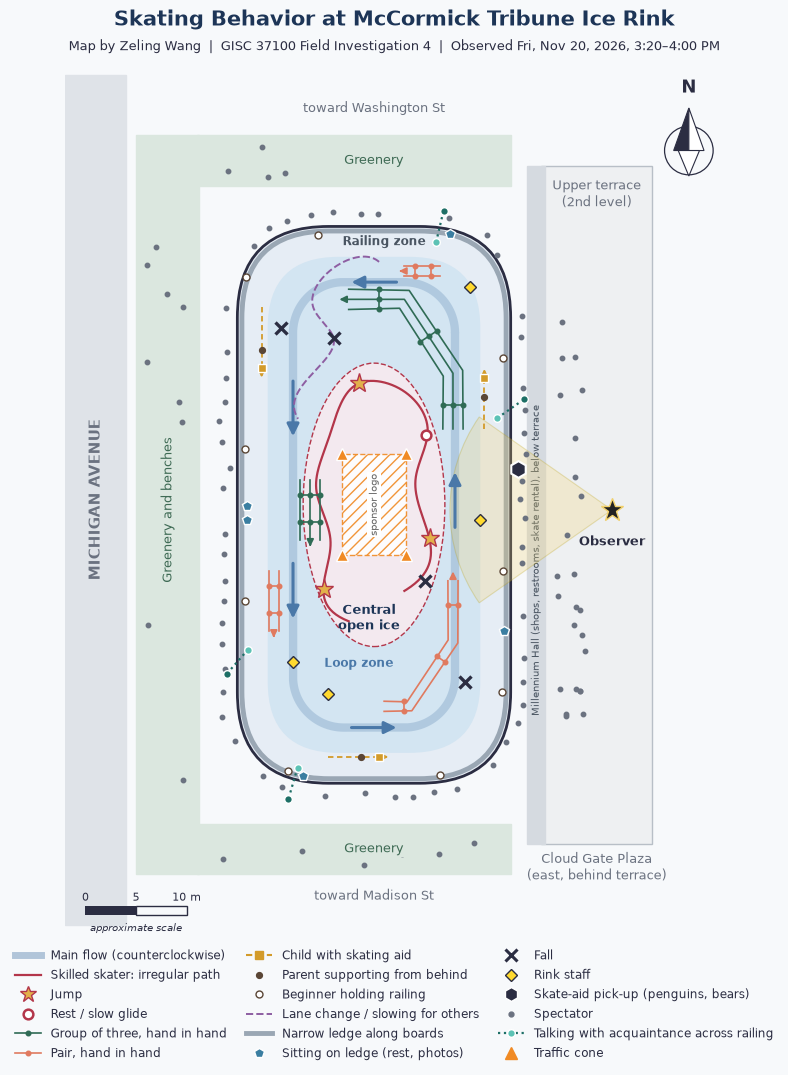

In [161]:
leg = [
    Line2D([], [], color='#4a78a8', lw=5, alpha=.4, label='Main flow (counterclockwise)'),
    Line2D([], [], color='#b3364a', lw=1.6, label='Skilled skater: irregular path'),
    Line2D([], [], color='#e2b04a', mec='#b3364a', marker='*', ls='', ms=12, label='Jump'),
    Line2D([], [], marker='o', ls='', mfc='white', mec='#b3364a', mew=1.8, ms=7, label='Rest / slow glide'),
    Line2D([], [], color='#2f6b55', lw=1.2, marker='o', ms=3.3, label='Group of three, hand in hand'),
    Line2D([], [], color='#e07a5f', lw=1.2, marker='o', ms=3.3, label='Pair, hand in hand'),
    Line2D([], [], color='#d39b2a', marker='s', ls=(0, (3, 2)), ms=6, label='Child with skating aid'),
    Line2D([], [], color='#5a4636', marker='o', ls='', ms=4.2, label='Parent supporting from behind'),
    Line2D([], [], marker='o', ls='', mfc='#ffffff', mec='#5a4636', ms=5, label='Beginner holding railing'),
    Line2D([], [], color='#8e5ea2', ls='--', lw=1.4, label='Lane change / slowing for others'),
    Line2D([], [], color='#9aa7b4', lw=3.5, label='Narrow ledge along boards'),
    Line2D([], [], marker='p', ls='', ms=7, color='#3b7ea1', mec='white', label='Sitting on ledge (rest, photos)'),
    Line2D([], [], color='#2b2d42', marker='x', ls='', ms=8, mew=2.2, label='Fall'),
    Line2D([], [], marker='D', ls='', ms=6, color='#ffd92f', mec='#2b2d42', label='Rink staff'),
    Line2D([], [], marker='h', ls='', ms=10, color='#2b2d42', mec='white', label='Skate-aid pick-up (penguins, bears)'),
    Line2D([], [], marker='o', ls='', ms=3.5, color='#6b7280', label='Spectator'),
    Line2D([], [], color='#1d6f66', ls=':', lw=1.6, marker='o', mfc='#5cc2b5', mec='white', ms=5.5, label='Talking with acquaintance across railing'),
    Line2D([], [], marker='^', ls='', ms=8, color='#f08a24', label='Traffic cone'),
]
fig.legend(handles=leg, loc='lower center', ncol=3, fontsize=8.6, frameon=False, bbox_to_anchor=(.5, .01),
           handlelength=2.2, columnspacing=1.6, labelspacing=.55)

fig.suptitle('Skating Behavior at McCormick Tribune Ice Rink',
             fontsize=15, fontweight='bold', y=.975, color='#1d3557')
fig.text(.5, .938, 'Map by Zeling Wang  |  GISC 37100 Field Investigation 4  |  Observed Fri, Nov 20, 2026, 3:20–4:00 PM',
         ha='center', fontsize=9.5, color='#2b2d42')
plt.subplots_adjust(top=.925, bottom=.128, left=.03, right=.97)
fig.savefig('rink_map.png', dpi=200, facecolor=fig.get_facecolor()); fig.savefig('rink_map.pdf', facecolor=fig.get_facecolor())
display(fig)
